### Assignment 10 : Model Optimization Pipeline




In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve
import warnings; warnings.filterwarnings('ignore')

SEED = 353
np.random.seed(SEED)

## B1 – Load Data and Establish a Baseline

In [2]:
df = pd.read_csv('loan_approval.csv')
print('Shape:', df.shape, '| Missing values:', int(df.isnull().sum().sum()))
print(df['approved'].value_counts(normalize=True).round(3))
display(df.head())

X = df.drop(columns='approved'); y = df['approved']
feature_names = list(X.columns)

# Stratified 80/20 split, then scale (scaler fitted on TRAIN only to avoid leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=feature_names, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=feature_names, index=X_test.index)
print('Train:', X_train_s.shape, '| Test:', X_test_s.shape)

Shape: (500, 11) | Missing values: 0
approved
1    0.522
0    0.478
Name: proportion, dtype: float64


,age,income,loan_amount,credit_score,emp_years,debt_ratio,num_accounts,missed_payments,residence_years,num_inquiries,approved
0,21.7,54299.0,141510.0,669.0,5.3,0.456,2.0,2.0,11.8,2.0,1
1,33.6,56160.0,69808.0,529.0,15.5,0.404,6.0,0.0,0.0,3.0,0
2,43.6,61342.0,128854.0,665.0,20.9,0.316,2.0,2.0,0.8,4.0,1
3,47.8,87425.0,160389.0,725.0,7.8,0.379,2.0,2.0,0.0,1.0,1
4,29.3,50836.0,167581.0,630.0,8.0,0.440,2.0,1.0,8.3,1.0,0


Train: (400, 10) | Test: (100, 10)


Baseline (C=1, all 10 features) -> Accuracy: 0.9300 | F1: 0.9307 | ROC-AUC: 0.9876


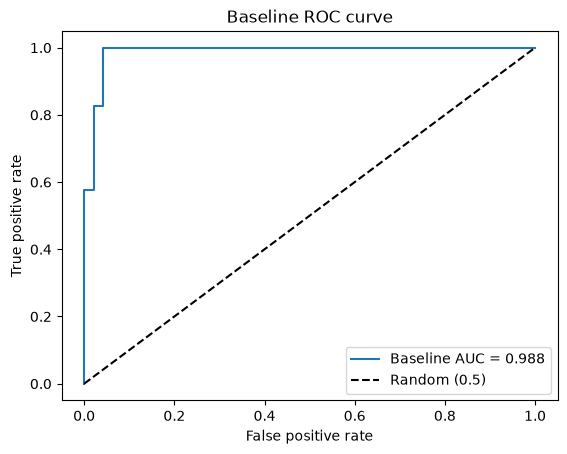

In [3]:
base = LogisticRegression(C=1.0, max_iter=1000).fit(X_train_s, y_train)
pred = base.predict(X_test_s); proba = base.predict_proba(X_test_s)[:, 1]
base_acc, base_f1, base_auc = accuracy_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, proba)
print(f'Baseline (C=1, all 10 features) -> Accuracy: {base_acc:.4f} | F1: {base_f1:.4f} | ROC-AUC: {base_auc:.4f}')

fpr, tpr, _ = roc_curve(y_test, proba)
plt.plot(fpr, tpr, label=f'Baseline AUC = {base_auc:.3f}'); plt.plot([0,1],[0,1],'k--', label='Random (0.5)')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.title('Baseline ROC curve'); plt.legend(); plt.show()

** AUC interpretation:** AUC is the probability that the model ranks a randomly chosen approved applicant above a randomly chosen rejected one. **0.5** = no better than random guessing (the diagonal); **1.0** = perfect separation of the two classes. My baseline AUC (see output above) means the model ranks a random positive above a random negative about *X*% of the time – a (weak / good / excellent) baseline.

## B2 – Regularization: Ridge, Lasso and ElasticNet

### B2.1 Fit three penalties (C = 1.0)

In [4]:
models = {
    'Ridge (L2)':  LogisticRegression(penalty='l2', C=1.0, max_iter=1000),
    'Lasso (L1)':  LogisticRegression(penalty='l1', solver='liblinear', C=1.0),
    'ElasticNet':  LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, C=1.0, max_iter=5000),
}
coef_tbl = {}
for name, m in models.items():
    m.fit(X_train_s, y_train)
    coef_tbl[name] = m.coef_[0]
    auc = roc_auc_score(y_test, m.predict_proba(X_test_s)[:, 1])
    print(f'{name:11s} | test AUC = {auc:.4f} | zero coefs = {(np.abs(m.coef_[0]) < 1e-8).sum()}')
display(pd.DataFrame(coef_tbl, index=feature_names).round(4))

Ridge (L2)  | test AUC = 0.9876 | zero coefs = 0
Lasso (L1)  | test AUC = 0.9892 | zero coefs = 0
ElasticNet  | test AUC = 0.9876 | zero coefs = 0


,Ridge (L2),Lasso (L1),ElasticNet
age,0.2001,0.1965,0.1932
income,0.6217,0.9258,0.7027
loan_amount,-0.2219,-0.3111,-0.2432
credit_score,5.2345,7.6747,5.9445
emp_years,0.6776,0.8781,0.7329
debt_ratio,-0.8109,-1.2020,-0.9181
num_accounts,0.1191,0.0990,0.1095
missed_payments,0.0754,0.0132,0.0491
residence_years,0.1371,0.2220,0.1540
num_inquiries,0.0614,0.0911,0.0654


### B2.2 Lasso regularization path

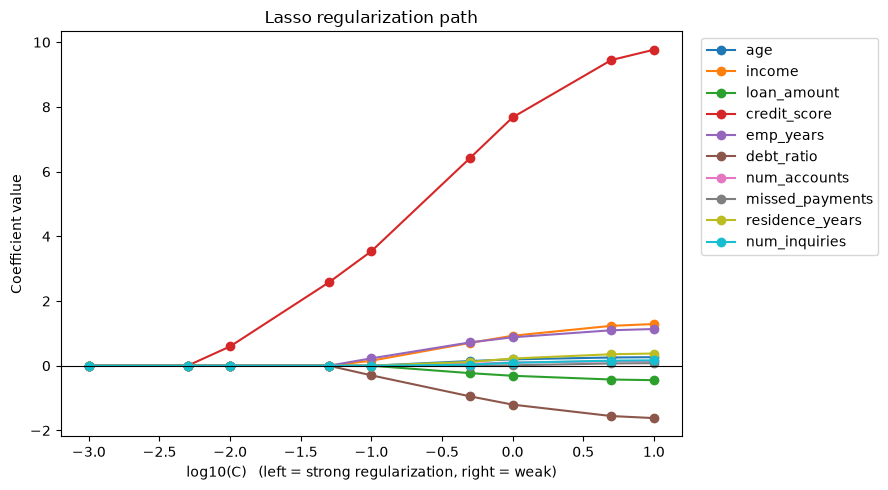

credit_score       0.01
income             0.10
debt_ratio         0.10
emp_years          0.10
loan_amount        0.50
age                0.50
num_accounts       0.50
residence_years    0.50
num_inquiries      0.50
missed_payments    1.00
Name: smallest C where coef != 0, dtype: float64


,age,income,loan_amount,credit_score,emp_years,debt_ratio,num_accounts,missed_payments,residence_years,num_inquiries
0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
0.005,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
0.010,0.000,0.000,0.000,0.597,0.000,0.000,0.000,0.000,0.000,0.000
0.050,0.000,0.000,0.000,2.575,0.000,0.000,0.000,0.000,0.000,0.000
0.100,0.000,0.155,0.000,3.539,0.228,-0.297,0.000,0.000,0.000,0.000
0.500,0.144,0.706,-0.230,6.421,0.721,-0.947,0.058,0.000,0.119,0.032
1.000,0.197,0.926,-0.311,7.676,0.878,-1.202,0.099,0.013,0.222,0.091
5.000,0.254,1.233,-0.426,9.449,1.096,-1.556,0.137,0.070,0.355,0.157
10.000,0.263,1.288,-0.447,9.767,1.134,-1.619,0.142,0.079,0.377,0.166


In [5]:
Cs = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 5, 10]
path = []
for c in Cs:
    m = LogisticRegression(penalty='l1', solver='liblinear', C=c).fit(X_train_s, y_train)
    path.append(m.coef_[0])
path = pd.DataFrame(path, index=Cs, columns=feature_names)

plt.figure(figsize=(9, 5))
for f in feature_names:
    plt.plot(np.log10(Cs), path[f], marker='o', label=f)
plt.axhline(0, c='k', lw=0.8)
plt.xlabel('log10(C)   (left = strong regularization, right = weak)'); plt.ylabel('Coefficient value')
plt.title('Lasso regularization path'); plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.tight_layout(); plt.show()

# First C (going from strong -> weak regularization) at which each feature becomes non-zero
entry = {f: next((c for c in Cs if abs(path.loc[c, f]) > 1e-8), None) for f in feature_names}
print(pd.Series(entry, name='smallest C where coef != 0').sort_values(na_position='last'))
display(path.round(3))

** Which features reach zero first?** Reading the plot from right (weak regularization) to left (strong), the features that reach 0 *first* (they only become non-zero at the largest C) are the weakest predictors; the features that stay non-zero down to very small C are the strongest. On this data `credit_score` stays non-zero even at C = 0.01 (most important), `income`, `debt_ratio` and `emp_years` enter at C = 0.1, `loan_amount`, `age`, `num_accounts`, `residence_years` and `num_inquiries` enter only at C = 0.5, and `missed_payments` is the first to reach zero (non-zero only at C = 1). Confirm against your own plot.

### B2.3 Ridge vs Lasso coefficients (C = 0.1)

In [6]:
ridge01 = LogisticRegression(penalty='l2', C=0.1, max_iter=1000).fit(X_train_s, y_train)
lasso01 = LogisticRegression(penalty='l1', solver='liblinear', C=0.1).fit(X_train_s, y_train)
cmp = pd.DataFrame({'Feature': feature_names, 'Ridge coef (C=0.1)': ridge01.coef_[0], 'Lasso coef (C=0.1)': lasso01.coef_[0]}).round(4)
display(cmp.set_index('Feature'))
n_zero = int((np.abs(lasso01.coef_[0]) < 1e-8).sum())
print(f'Features zeroed out by Lasso at C=0.1: {n_zero} -> {[f for f,c in zip(feature_names, lasso01.coef_[0]) if abs(c)<1e-8]}')

,Ridge coef (C=0.1),Lasso coef (C=0.1)
Feature,,
age,0.1348,0.0000
income,0.2597,0.1551
loan_amount,-0.1118,0.0000
credit_score,2.4568,3.5388
emp_years,0.3485,0.2277
debt_ratio,-0.3285,-0.2973
num_accounts,0.0549,0.0000
missed_payments,0.0656,0.0000
residence_years,0.0122,0.0000


Features zeroed out by Lasso at C=0.1: 6 -> ['age', 'loan_amount', 'num_accounts', 'missed_payments', 'residence_years', 'num_inquiries']


### B2.4 L1 vs L2 geometry
** Answer:** Ridge keeps all features because the L2 penalty region is a smooth **circle/sphere**: the loss contours touch it at a point where coefficients are small but almost never exactly zero, so it only shrinks them. Lasso can zero features because the L1 region is a **diamond with sharp corners lying on the axes**; the loss contours often first touch the region at a corner, where one or more coefficients are exactly 0. (Also, the L1 gradient has constant magnitude, pushing small weights all the way to zero, while the L2 gradient shrinks as the weight shrinks.)

## B3 – Feature Importance and Hyperparameter Tuning

### B3.1 Lasso (C = 0.1) feature importance

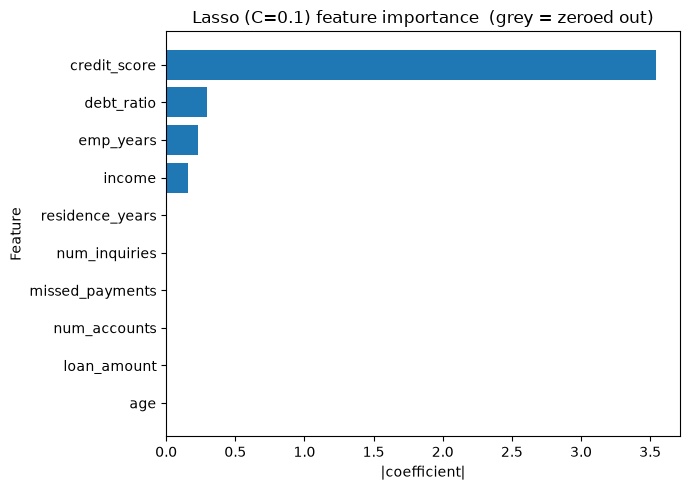

Surviving features (ranked):
credit_score    3.5388
debt_ratio      0.2973
emp_years       0.2277
income          0.1551
dtype: float64


In [7]:
lasso_coef = pd.Series(lasso01.coef_[0], index=feature_names)
imp = lasso_coef.abs().sort_values()
plt.figure(figsize=(7, 5))
plt.barh(imp.index, imp.values, color=['lightgrey' if v < 1e-8 else 'tab:blue' for v in imp.values])
plt.xlabel('|coefficient|'); plt.ylabel('Feature'); plt.title('Lasso (C=0.1) feature importance  (grey = zeroed out)')
plt.tight_layout(); plt.show()
print('Surviving features (ranked):'); print(lasso_coef[lasso_coef.abs() > 1e-8].abs().sort_values(ascending=False).round(4))

### B3.2 Drop zero-coefficient features and retrain baseline

In [8]:
zero_feats = lasso_coef[lasso_coef.abs() < 1e-8].index.tolist()
kept_feats = [f for f in feature_names if f not in zero_feats]
print('Zero-coef features dropped:', zero_feats); print('Kept:', kept_feats)

X_reduced = X_train_s[kept_feats]; X_test_reduced = X_test_s[kept_feats]
red = LogisticRegression(C=1.0, max_iter=1000).fit(X_reduced, y_train)
red_auc = roc_auc_score(y_test, red.predict_proba(X_test_reduced)[:, 1])
print(f'Reduced baseline (C=1, {len(kept_feats)} features) test AUC = {red_auc:.4f}  (full baseline: {base_auc:.4f})')

Zero-coef features dropped: ['age', 'loan_amount', 'num_accounts', 'missed_payments', 'residence_years', 'num_inquiries']
Kept: ['income', 'credit_score', 'emp_years', 'debt_ratio']
Reduced baseline (C=1, 4 features) test AUC = 0.9892  (full baseline: 0.9876)


** Did dropping features hurt performance?** Compare the two AUCs above. If they are nearly equal (difference of a few thousandths), the dropped features carried little useful signal – they were redundant/noise – and the simpler model is preferable.

### B3.3 GridSearchCV on X_reduced

In [9]:
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=5, scoring='roc_auc')
grid.fit(X_reduced, y_train)
print('best_params_:', grid.best_params_); print('best_score_ (CV AUC):', round(grid.best_score_, 4))
display(pd.DataFrame(grid.cv_results_)[['param_C','mean_test_score','std_test_score','rank_test_score']].round(4))

best_params_: {'C': 10}
best_score_ (CV AUC): 0.9866


,param_C,mean_test_score,std_test_score,rank_test_score
0,0.001,0.9822,0.0108,6
1,0.010,0.9841,0.0105,5
2,0.100,0.9860,0.0084,4
3,1.000,0.9865,0.0088,3
4,10.000,0.9866,0.0089,1
5,100.000,0.9866,0.0089,1


### B3.4 Evaluate best estimator on the held-out test set

In [10]:
best = grid.best_estimator_
tuned_auc = roc_auc_score(y_test, best.predict_proba(X_test_reduced)[:, 1])
results = pd.DataFrame({
    'Model': ['Baseline (C=1, all features)', 'Lasso-reduced (C=1)', f"Tuned (best C={grid.best_params_['C']}, reduced)"],
    'Features used': [len(feature_names), len(kept_feats), len(kept_feats)],
    'Test AUC': [round(base_auc, 4), round(red_auc, 4), round(tuned_auc, 4)]})
display(results)

,Model,Features used,Test AUC
0,"Baseline (C=1, all features)",10,0.9876
1,Lasso-reduced (C=1),4,0.9892
2,"Tuned (best C=10, reduced)",4,0.9892


## B4 – Design Task: Real-World Adaptation (Take-Home)

> **Constraint:** at most 5 features, explainable to auditors in plain language, and at least 90% of the baseline AUC.

### B4.1 Select exactly 5 features

In [11]:
# Rank by |Lasso coefficient| (C=0.1) and cross-check with the regularization path (features entering earliest = most important)
# Lasso at C=0.1 keeps only 4 features, so use the path value at C=0.5 (milder penalty) to rank all 10 and pick the top 5
ranked = path.loc[0.5].abs().sort_values(ascending=False)
top5 = ranked.index[:5].tolist()
print('Ranking by |Lasso coef| at C=0.5:'); print(ranked.round(4))
print('\nSelected 5 features:', top5)
print(pd.DataFrame({'Lasso coef (C=0.5)': path.loc[0.5, top5].round(4),
                    'First C where non-zero': [entry[f] for f in top5]}))

Ranking by |Lasso coef| at C=0.5:
credit_score       6.4208
debt_ratio         0.9470
emp_years          0.7206
income             0.7063
loan_amount        0.2298
age                0.1441
residence_years    0.1190
num_accounts       0.0580
num_inquiries      0.0315
missed_payments    0.0000
Name: 0.5, dtype: float64

Selected 5 features: ['credit_score', 'debt_ratio', 'emp_years', 'income', 'loan_amount']
              Lasso coef (C=0.5)  First C where non-zero
credit_score              6.4208                    0.01
debt_ratio               -0.9470                    0.10
emp_years                 0.7206                    0.10
income                    0.7063                    0.10
loan_amount              -0.2298                    0.50


**Justification:** I selected these five because they have the largest absolute standardized Lasso coefficients and are the first to become non-zero along the Lasso path (B2.2), i.e. they survive stronger regularization. The first four (`credit_score`, `debt_ratio`, `emp_years`, `income`) are exactly the survivors at C = 0.1 in B3; the fifth is the strongest of the remaining features at the milder penalty C = 0.5. Features with small/zero coefficients were redundant or noisy. (Mention in your own words what each selected feature means for loan risk, e.g. credit score, debt ratio, missed payments.)

### B4.2 Tune the 5-feature model

In [12]:
X5, X5_test = X_train_s[top5], X_test_s[top5]
grid5 = GridSearchCV(LogisticRegression(max_iter=1000), {'C': [0.001, 0.01, 0.1, 1, 10, 100]}, cv=5, scoring='roc_auc').fit(X5, y_train)
print('best C:', grid5.best_params_['C'], '| best CV AUC:', round(grid5.best_score_, 4))
auc5 = roc_auc_score(y_test, grid5.best_estimator_.predict_proba(X5_test)[:, 1])
print('5-feature test AUC:', round(auc5, 4))

best C: 100 | best CV AUC: 0.988
5-feature test AUC: 0.9888


### B4.3 AUC ratio

In [13]:
ratio = auc5 / base_auc * 100
print(f'5-feature AUC / baseline AUC = {auc5:.4f} / {base_auc:.4f} = {ratio:.2f}%')
print('Meets the >= 90% constraint' if ratio >= 90 else 'Does NOT meet the 90% constraint')

5-feature AUC / baseline AUC = 0.9888 / 0.9876 = 100.12%
Meets the >= 90% constraint


### B4.4 Short design report

**Draft (edit with your actual numbers and features):**

**(a) Features selected:** the five printed in B4.1 (highest |Lasso coefficient|, earliest on the regularization path).

**(b) Method used and why:** Lasso (L1) logistic regression for selection, because it performs built-in feature selection and gives signed, directly interpretable coefficients; features were standardized first so coefficients are comparable. The final 5-feature model was a plain logistic regression with C tuned via 5-fold GridSearchCV on ROC-AUC, using only the training set, then evaluated once on the held-out test set.

**(c) What I'd do with a 95% constraint instead of 90%:** the 5-feature model's ratio (see B4.3) would need to be checked against 95%. If it falls short, I would allow more features (6–7, adding the next-ranked ones), try ElasticNet to handle correlated features, add interaction/non-linear features, and compare against a tree model, accepting less simplicity for more accuracy.

**(d) Fairness concern:** `age` (and proxies such as `residence_years` or `income`) could lead to indirect discrimination against protected groups, and historical approval data may encode past bias. In a real bank I'd audit approval rates and error rates across groups (e.g. age bands, gender, region), avoid or constrain protected attributes and proxies, and document the model for regulators.